# 🎯 Clustering (Unsupervised Learning)
**Task:** Implement K-Means clustering to group customers.  
**Requirements:** Apply K-Means, use elbow method/silhouette score, visualize using PCA.  
**Tools:** `pandas`, `scikit-learn`, `matplotlib`, `seaborn`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load Data
df = pd.read_csv('data/customer_churn.csv')
print('✅ Data loaded successfully')

# Drop target column 'Churn' for unsupervised learning if it exists
if 'Churn' in df.columns:
    df = df.drop(columns=['Churn'])
    print('Removed target label for clustering.')

# Preprocess numerical columns
df_num = df.select_dtypes(include='number').fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_num)
print('✅ Features Scaled')

✅ Data loaded successfully
Removed target label for clustering.
✅ Features Scaled


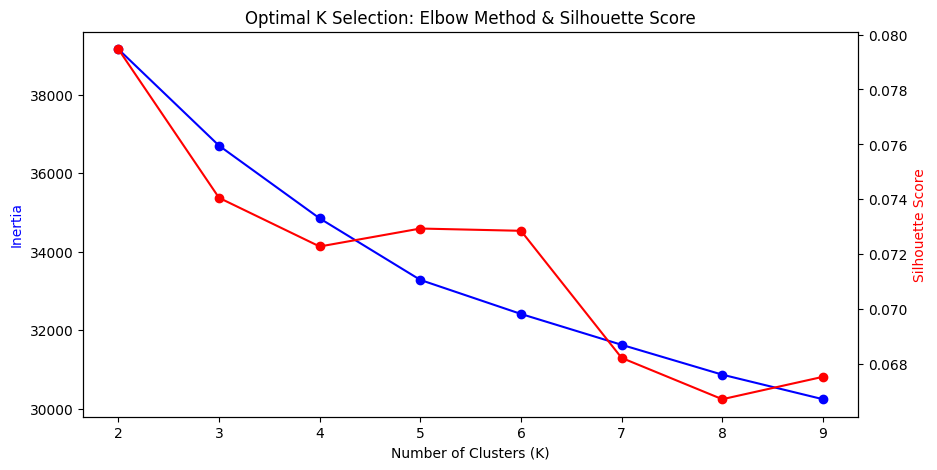

In [2]:
# Determine Optimal K using Elbow Method & Silhouette Score
inertias = []
silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plotting
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(K_range, inertias, 'bo-', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia', color='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, 'ro-', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')

plt.title('Optimal K Selection: Elbow Method & Silhouette Score')
plt.show()

In [3]:
# Apply K-Means with Optimal K (e.g., K=3 or 4 based on analysis)
optimal_k = 3 # You can change this based on the plot
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df_num['Cluster'] = clusters
print(f'✅ K-Means applied with K={optimal_k}')

✅ K-Means applied with K=3


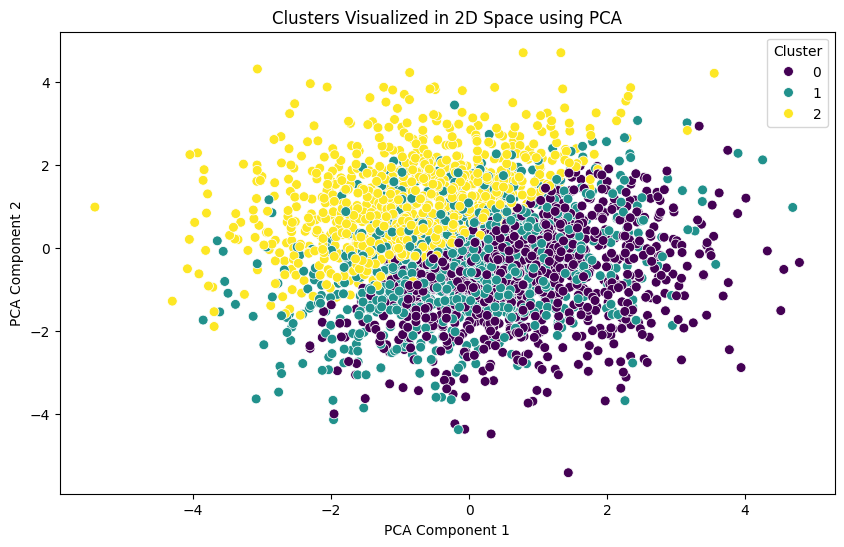

In [4]:
# Dimensionality Reduction and Visualization using PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=clusters, palette='viridis', s=50)
plt.title('Clusters Visualized in 2D Space using PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.show()

In [5]:

import joblib
import os

os.makedirs('outputs', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Save kmeans model and scaler
joblib.dump(kmeans, 'models/kmeans_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(pca, 'models/pca_model.pkl')

# Save clustered data
df_num.to_csv('outputs/clustered_data.csv', index=False)
print('✅ Saved models and outputs successfully!')


✅ Saved models and outputs successfully!
